# Late-night browsing on Taobao: impulse buying or idle scrolling?

**Business problem.** Platforms price ads and schedule push notifications by hour. A common belief is that late-night
shoppers are impulsive: tired, less guarded, more likely to "just buy it". If true, late-night traffic deserves *higher* bids.
The opposite view is that late-night browsing is mostly idle scrolling, so the same click is worth *less*. The direction is not
obvious in advance, and it matters for how much a platform should pay for an hour of traffic.

**Questions.**
1. Does a product first viewed late at night (22–01) or in the small hours (02–05) convert less or more than one first viewed in the
   daytime (09–17), for the same user and the same item?
2. If it converts less, is the purchase *lost* or only *delayed* to the next day? (survival analysis)
3. Is the late-night gap the same for everyone, or larger for some users and items? (Causal Forest)

**Data.** Alibaba Tianchi UserBehavior (dataset 649): 100,150,807 raw events, 987,994 users, 4,162,024 items, 2017-11-25 to
2017-12-03 (Asia/Shanghai). Fields: user, item, category, behaviour (pv / fav / cart / buy), Unix timestamp. There is no price,
revenue, dwell time or psychology. The Tianchi host was unreachable (TLS reset), so the file was downloaded from a public Kaggle
mirror; the hash and counts are recorded in the parent project's `data/source_manifest.json`.

**Unit of analysis.** One user-item *first-view episode*: `t0` = first observed view of that item by that user. The time-of-day
bin is the Shanghai hour of `t0`. Outcomes: `Y1` = bought the item within 1 h of `t0`, `Y2` = within 24 h. Unlike the parent
project, instant buyers are kept, because impulse buying is exactly what is being tested.

**How this notebook runs.** The full pipeline takes about 2 h and up to 22 GB RAM (`README.md`). This notebook does not refit
the survival models or the Causal Forest. It re-computes live (a) the descriptives on all 51.3 M episodes, (b) the primary
fixed-effects model on the 9.3 M-episode main sample, and (c) the test-set cumulative purchase curves, and asserts each equals the
saved result. Everything else is read from `results/` and `figures/`. Plans were saved locally before results were seen
(`ANALYSIS_PLAN.md`, `ANALYSIS_PLAN_ADVANCED.md`; not externally registered). Deviations are in `POST_PLAN_DEVIATIONS.md`.

In [1]:
import os, sys, json, importlib
from pathlib import Path
EXT = Path.cwd()
assert (EXT / 'ANALYSIS_PLAN_ADVANCED.md').exists(), 'run with cwd = extension_night_browsing'
PARENT = EXT.parent
sys.path.insert(0, str(EXT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from statsmodels.stats.multitest import multipletests
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
RES = EXT / 'results'; FIG = EXT / 'figures'
COL = {'day': '#555555', 'evening': '#3B6DFF', 'late': '#E07B39', 'small': '#2CA58D', 'morning': '#9B6BCC'}
ORDER = ['day', 'evening', 'late', 'small', 'morning']
models = importlib.import_module('02_models')       # derive(), describe(), fit_multi() used by the pipeline
print(sys.version.split()[0], '| pandas', pd.__version__, '| numpy', np.__version__)

3.13.9 | pandas 2.3.3 | numpy 2.3.5


## 1. Data source and raw-data quality (parent project audit)

In [2]:
m = json.loads((PARENT / 'data/source_manifest.json').read_text())
for k in ['original_catalog_url', 'official_download_status', 'actual_source_catalog_url', 'independent_corroboration']:
    print(f'{k}: {m[k]}')
print('csv sha256:', m['csv']['sha256'])
a = json.loads((PARENT / 'results/data_audit.json').read_text())
print('\nraw rows', f"{a['raw_rows']:,}", '| users', f"{a['distinct_users_raw']:,}", '| items', f"{a['distinct_items_raw']:,}")
print('missing values per column:', a['null_counts'])
print('behaviour codes:', a['behavior_raw_values'], '| unrecognised:', a['unrecognised_behavior_rows'])
t = a['timestamp']
print('raw timestamp range:', t['min_utc'], '->', t['max_utc'], '(corrupt values exist)')
print('kept window:', t['window_definition'], '| rows before:', t['rows_before_window'], '| after:', t['rows_after_window'])
print('exact duplicate extra copies collapsed:', a['duplicates_in_window']['exact_duplicate_rows_extra_copies'])

original_catalog_url: https://tianchi.aliyun.com/dataset/649
official_download_status: NOT obtained directly: tianchi.aliyun.com TLS handshake reset (curl SSL_ERROR_SYSCALL, Python SSLEOFError) on repeated attempts on 2026-10-21; no login/agreement was attempted.
actual_source_catalog_url: https://www.kaggle.com/datasets/marwa80/userbehavior
independent_corroboration: Second public Kaggle mirror https://www.kaggle.com/datasets/haicaochi/userbehavior: ZIP central directory (tail range request only) lists UserBehavior/UserBehavior.csv with identical CRC32 0a9e6c7e; full second copy not downloaded.
csv sha256: 46fdd7d389c1ddc7922eb7d9014af5573a4a3045da28c6c46197636873d8f1a9

raw rows 100,150,807 | users 987,994 | items 4,162,024
missing values per column: {'row_no': 0, 'user_id': 0, 'item_id': 0, 'category_id': 0, 'behavior': 0, 'behavior_raw': 0, 'ts': 0}
behaviour codes: {'pv': 89716264, 'cart': 5530446, 'fav': 2888258, 'buy': 2015839} | unrecognised: 0
raw timestamp range: 1902-05-07 2

**Quality issues and how they were handled.** No missing values. Timestamps contain corrupt values (1902, 2037) and a
small number of events just outside the 9-day window; 55,576 such rows are excluded from analysis (kept in the raw file).
Exact duplicate rows are collapsed. Same-second events of different types are treated as simultaneous. Timestamps are converted
from Unix seconds to Asia/Shanghai local time, because "late night" must be the shopper's local clock.

## 2. Data preparation: from 100 M events to 51.3 M first-view episodes

In [3]:
wf = json.loads((RES / 'sample_waterfall.json').read_text())
display(pd.DataFrame(wf['waterfall'], columns=['step', 'remaining_user_item_pairs']).set_index('step'))
print(f"final: {wf['episodes']:,} episodes | {wf['users']:,} users | {wf['items']:,} items")

,remaining_user_item_pairs
step,
user_item_pairs_with_pv,71015192
t0_after_1d_washout,62913949
complete_24h_outcome_window,53612459
no_fav_cart_buy_before_t0,51316512


final: 51,316,512 episodes | 983,132 users | 3,621,644 items


Each step removes episodes whose `t0` is not comparable:
- `t0_after_1d_washout`: at least 24 h of observed history before `t0`, so "first view" is less likely to be a repeat view.
- `complete_24h_outcome_window`: the 24-h outcome window lies fully inside the study period.
- `no_fav_cart_buy_before_t0`: the user had not already favourited, carted or bought the item.

About 40% of buy pairs in the 9 days have no earlier view, fav or cart of that item, so they never form an episode. The results
cover only the *view-then-buy* path.

In [4]:
full = models.derive(pd.read_parquet(EXT / 'data/episodes_hour.parquet'))
print(f'{len(full):,} rows'); print(full.dtypes.to_string())

51,316,512 rows
user_id           int32
item_id           int32
t0                int64
buy_delay_s       int64
hour               int8
day                int8
hist_pv24         int32
hist_pv1h         int32
hist_buy24      float64
pop24             int32
bucket            int16
top1pct_user       int8
y1              float64
y2              float64
y10m            float64
y3              float64
bin              object
evening         float64
late            float64
small           float64
morning         float64
l_hpv24         float64
l_hpv1h         float64
l_pop           float64
dayhour           int64


**Variables.**
- Keys: `user_id`, `item_id`.
- Time: `t0` (Unix s), `hour` (Shanghai hour of `t0`), `day` (0 = Sat 2017-11-25).
- Outcome raw: `buy_delay_s` = seconds from `t0` to the first purchase of the item; −1 if no purchase in the period.
- Pre-`t0` controls: `hist_pv24` and `hist_pv1h` = the user's views of any item in the previous 24 h / 1 h, `hist_buy24` = any
  purchase in the previous 24 h, `pop24` = the item's views by all users in the previous 24 h.
- `bucket` = md5(user_id) mod 100, used for samples and splits.

**Created by `derive()`.** `y1`, `y2` (0/100, so coefficients read as percentage points), `y10m`, `y3` (bought in 1–24 h), `bin`
(time-of-day bin), bin dummies, log2 controls, `dayhour`.

In [5]:
checks = {
    'missing values (any column)': int(full[['user_id', 'item_id', 't0', 'buy_delay_s', 'hour', 'day', 'pop24']].isna().sum().sum()),
    'duplicate user-item episodes': int(full.duplicated(['user_id', 'item_id']).sum()),
    'hour outside 0..23': int((~full.hour.between(0, 23)).sum()),
    'buy_delay_s < -1': int((full.buy_delay_s < -1).sum()),
    'negative history counts': int((full[['hist_pv24', 'hist_pv1h', 'pop24']] < 0).sum().sum()),
}
display(pd.Series(checks, name='count'))
assert sum(checks.values()) == 0
print('day range', full.day.min(), '-', full.day.max(), '| bins:', full.bin.value_counts().reindex(ORDER).to_dict())

missing values (any column)     0
duplicate user-item episodes    0
hour outside 0..23              0
buy_delay_s < -1                0
negative history counts         0
Name: count, dtype: int64

day range 1 - 8 | bins: {'day': 22334075, 'evening': 13704099, 'late': 10170764, 'small': 1377094, 'morning': 3730480}


## 3. Exploratory analysis

### 3.1 Live recomputation of the descriptives on all 51.3 M episodes

In [6]:
live = models.describe(full)
saved = pd.read_csv(RES / 'descriptives_full.csv')
live['level'] = live.level.astype(str); saved['level'] = saved.level.astype(str)
key = ['grouping', 'level']
lv, sv = live.set_index(key).sort_index(), saved.set_index(key).sort_index()[live.columns.drop(key)]
assert lv.index.equals(sv.index) and np.allclose(lv.to_numpy(float), sv.to_numpy(float))
print('live descriptives equal saved results/descriptives_full.csv')
desc_bin = lv.loc['bin'].reindex(ORDER)
display(desc_bin[['episodes', 'users', 'share_of_episodes_pct', 'y1_pct', 'y2_pct', 'share_of_24h_buys_pct']].round(3))

live descriptives equal saved results/descriptives_full.csv


,episodes,users,share_of_episodes_pct,y1_pct,y2_pct,share_of_24h_buys_pct
level,,,,,,
day,22334075,935967,43.522,0.774,1.159,50.177
evening,13704099,851347,26.705,0.675,0.938,24.919
late,10170764,700136,19.820,0.559,0.798,15.729
small,1377094,155939,2.684,0.471,0.842,2.248
morning,3730480,477356,7.270,0.528,0.958,6.927


The late bin holds 19.8% of all first views but only 15.7% of the 24-h purchases. Raw `Y1` is 0.56% late at night against
0.77% in the daytime. Raw differences can come from *who* browses at night and *which items* they view, so they are
only a starting point.

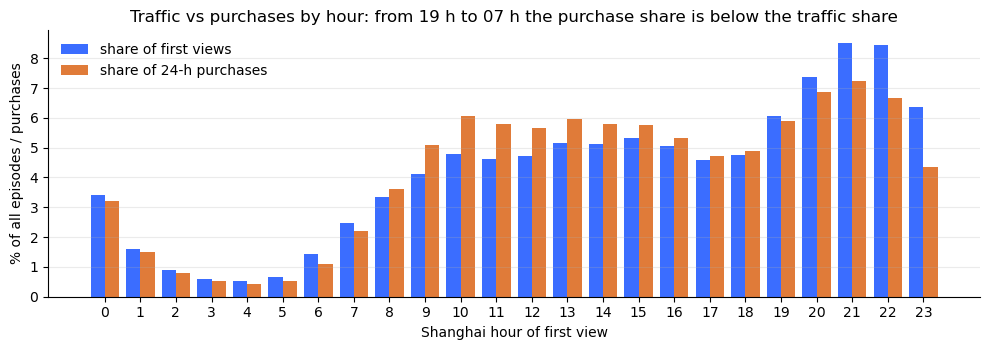

purchase share minus traffic share, pp: {0: -0.21, 1: -0.11, 2: -0.1, 3: -0.09, 4: -0.1, 5: -0.15, 6: -0.34, 7: -0.27, 8: 0.27, 9: 0.95, 10: 1.29, 11: 1.18, 12: 0.94, 13: 0.81, 14: 0.66, 15: 0.43, 16: 0.28, 17: 0.12, 18: 0.14, 19: -0.15, 20: -0.51, 21: -1.26, 22: -1.77, 23: -2.01}


In [7]:
hr = lv.loc['hour'].copy(); hr.index = hr.index.astype(int); hr = hr.sort_index()
fig, ax = plt.subplots(figsize=(10, 3.6))
w = .4
ax.bar(hr.index - w / 2, hr.share_of_episodes_pct, w, color='#3B6DFF', label='share of first views')
ax.bar(hr.index + w / 2, hr.share_of_24h_buys_pct, w, color='#E07B39', label='share of 24-h purchases')
ax.set_xticks(range(24)); ax.set_xlabel('Shanghai hour of first view'); ax.set_ylabel('% of all episodes / purchases')
ax.set_title('Traffic vs purchases by hour: from 19 h to 07 h the purchase share is below the traffic share')
ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='y', alpha=.25)
plt.tight_layout(); plt.show()
gap = (hr.share_of_24h_buys_pct - hr.share_of_episodes_pct).round(2)
print('purchase share minus traffic share, pp:', gap.to_dict())

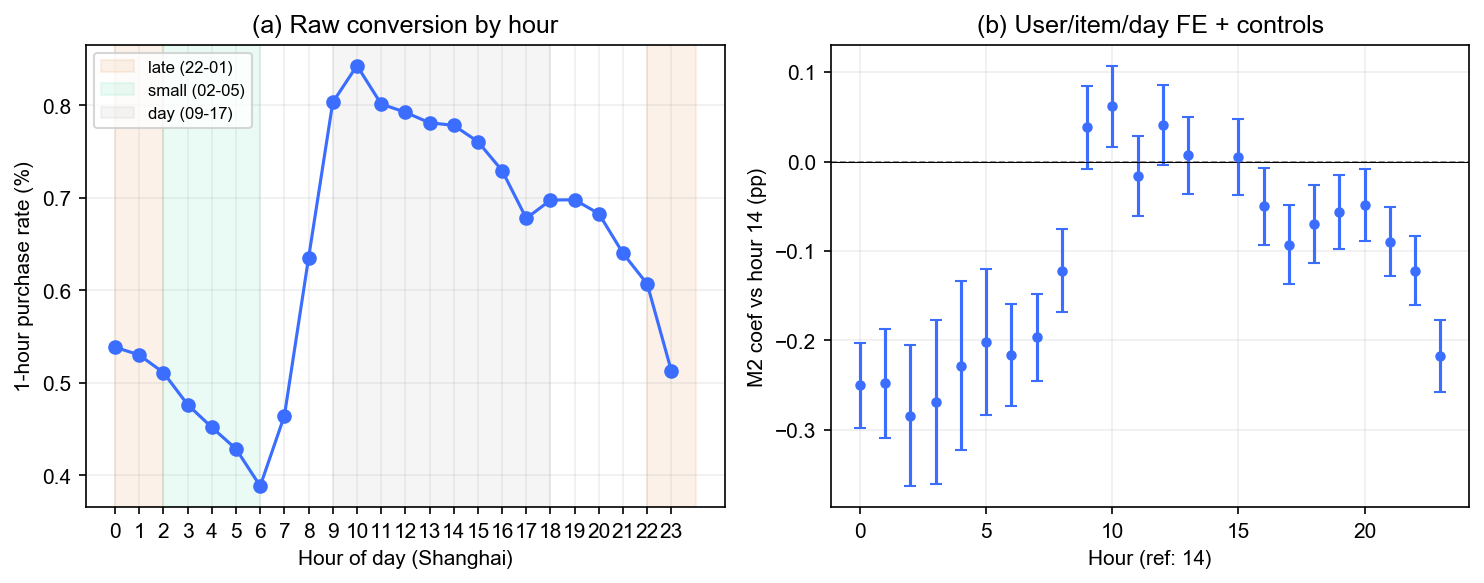

In [8]:
display(Image(filename=str(FIG / '01_hourly_shape.png')))

**Figure 01.** Left: the raw 1-h purchase rate by hour, with the late (22–01) and small-hours (02–05) bins shaded. Right: the
same hourly profile after user, item and date fixed effects and controls (reference hour 14). The night dip survives the
adjustment, so it is not just a different mix of users or items at night.

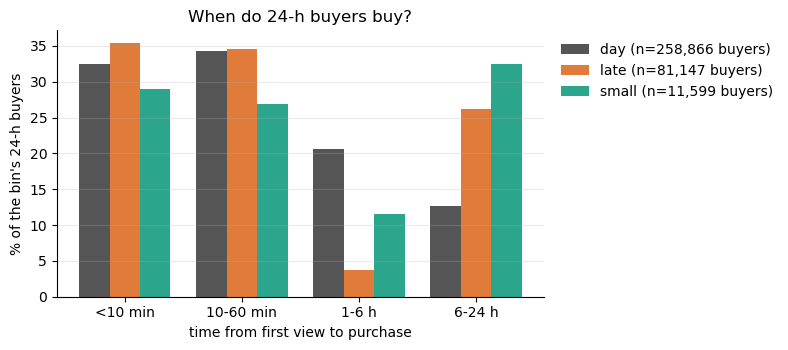

band,<10 min,10-60 min,1-6 h,6-24 h
bin,,,,
day,32.5,34.3,20.6,12.6
late,35.4,34.6,3.7,26.3
small,29.0,27.0,11.6,32.5


In [9]:
buyers = full.loc[(full.buy_delay_s >= 0) & (full.buy_delay_s < 86400) & full.bin.isin(['day', 'late', 'small']), ['bin', 'buy_delay_s']]
bands = ['<10 min', '10-60 min', '1-6 h', '6-24 h']
buyers['band'] = pd.cut(buyers.buy_delay_s / 60, [-1, 10, 60, 360, 1440], labels=bands, right=False)
comp = pd.crosstab(buyers.bin, buyers.band, normalize='index').reindex(['day', 'late', 'small']) * 100
fig, ax = plt.subplots(figsize=(8, 3.6)); w = .26
for k, b in enumerate(comp.index):
    x = np.arange(len(bands)) + (k - 1) * w
    ax.bar(x, comp.loc[b], w, color=COL[b], label=f'{b} (n={int((buyers.bin == b).sum()):,} buyers)')
ax.set_xticks(range(len(bands))); ax.set_xticklabels(bands)
ax.set_xlabel('time from first view to purchase'); ax.set_ylabel('% of the bin\'s 24-h buyers')
ax.set_title('When do 24-h buyers buy?'); ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(1.01, 1))
ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='y', alpha=.25)
plt.tight_layout(); plt.show()
comp.round(1)

About two-thirds of daytime buyers and 70% of late-night buyers buy within the first hour. What differs is the rest:
- **Late night:** almost nothing happens in hours 1–6 (3.7% of buyers), when viewers are presumably asleep. 26% of buyers buy the
  next morning (6–24 h).
- **Small hours:** a third of buyers (33%) buy in hours 6–24.
- **Daytime:** only 13% of buyers buy in hours 6–24.

This only describes buyers. Whether night viewers *in total* end up buying less, or just later, needs the survival models in
Section 5.

In [10]:
by_day = full[full.bin.isin(['day', 'late'])].pivot_table(index='day', columns='bin', values='y1', aggfunc='mean').round(3)
by_day['late_minus_day_pp'] = (by_day.late - by_day.day).round(3)
by_day

bin,day,late,late_minus_day_pp
day,,,
1,0.769,0.570,-0.199
2,0.827,0.610,-0.217
3,0.799,0.580,-0.219
4,0.812,0.603,-0.209
5,0.798,0.593,-0.205
6,0.715,0.503,-0.212
7,0.711,0.485,-0.226
8,NaN,0.641,NaN


Days 1–7 are the days with both daytime and late-night first views; day 8 (Dec 3) has only the few minutes after
midnight. On each of these 7 days the raw late-night `Y1` gap is between −0.20 and −0.23 pp, so it is not driven by one day or the
weekend.

## 4. Fixed-effects linear probability models

**Model.** For episode *i* of user *u* on item *j* on day *d*:

`Y_i = Σ_b β_b · 1[bin_i = b] + γ' X_i + α_u + δ_j + τ_d + ε_i`

- **Dependent variable:** `Y1` (bought within 1 h) or `Y2` (within 24 h), in percentage points.
- **Independent variables of interest:** dummies for evening, late, small and morning; daytime 09–17 is the reference.
- **Controls `X`** (all measured before `t0`): log2(1 + user's views in the previous 24 h), user bought in the previous 24 h,
  log2(1 + item views by everyone in the previous 24 h).
- **Fixed effects:** user `α_u` (stable shopping taste), item `δ_j` (item appeal and price level), day `τ_d` (promotions, weekday).
- **Inference:** standard errors two-way clustered by user and item. The 4 primary tests (late and small × Y1 and Y2) are
  Holm-corrected.

A linear probability model is used rather than logit because three high-dimensional fixed effects can be absorbed exactly and
coefficients read directly in percentage points. The main sample is user buckets 40–59 (a 20% user sample, complete histories);
buckets 60–79 are the replication sample.

In [11]:
main_s = full[full.bucket.between(40, 59)].copy()
del full
m2_live = models.fit_multi(main_s, models.DUM + models.CTRL, models.FE_MAIN, ['y1', 'y2'], 'M2_live')
saved_m2 = pd.read_csv(RES / 'model_coefficients.csv').query("model == 'M2_main' and cluster == 'user_id+item_id' and outcome in ['y1', 'y2']")
k = ['outcome', 'term']
lv, sv = m2_live.set_index(k).sort_index(), saved_m2.set_index(k).sort_index().loc[m2_live.set_index(k).sort_index().index]
assert np.allclose(lv.coef, sv.coef, atol=1e-6) and np.allclose(lv.se, sv.se, rtol=1e-4) and (lv.n == sv.n).all()
print(f"live M2 refit equals saved coefficients and SE | n = {int(lv.n.iloc[0]):,} episodes after {int(lv.n_dropped_singletons.iloc[0]):,} singletons dropped")
del main_s

00:44:57 M2_live n 9348719 114s


live M2 refit equals saved coefficients and SE | n = 9,348,719 episodes after 877,512 singletons dropped


In [12]:
coefs = pd.read_csv(RES / 'model_coefficients.csv').query("cluster == 'user_id+item_id'")
ladder = coefs[coefs.term.isin(['late', 'small']) & coefs.outcome.isin(['y1', 'y2'])].copy()
ladder['est'] = ladder.coef.map('{:+.3f}'.format) + ' [' + ladder.ci_low.map('{:.3f}'.format) + ', ' + ladder.ci_high.map('{:.3f}'.format) + ']'
tab = ladder.pivot_table(index='model', columns=['term', 'outcome'], values='est', aggfunc='first')
tab = tab.reindex(['M0_full', 'M0_main', 'M1_main', 'M2_main', 'M2_replication'])
tab['fe'] = coefs.groupby('model').fe.first(); tab['n'] = coefs.groupby('model').n.first()
tab

term                               late                                             small                                            fe         n
outcome                              y1                       y2                       y1                       y2                               
model                                                                                                                                            
M0_full         -0.215 [-0.224, -0.207]  -0.361 [-0.371, -0.351]  -0.303 [-0.320, -0.286]  -0.317 [-0.339, -0.294]                 none  51316512
M0_main         -0.232 [-0.250, -0.214]  -0.372 [-0.393, -0.351]  -0.281 [-0.319, -0.243]  -0.303 [-0.353, -0.253]                 none  10226231
M1_main         -0.229 [-0.249, -0.210]  -0.373 [-0.396, -0.350]  -0.294 [-0.336, -0.253]  -0.311 [-0.363, -0.260]              user_id  10225602
M2_main         -0.179 [-0.198, -0.160]  -0.307 [-0.330, -0.284]  -0.238 [-0.282, -0.194]  -0.230 [-0.285, -0.175]  user_id+item_id+day   9348719
M2_replication  -0.167 [-0.186, -0.147]  -0.298 [-0.321, -0.274]  -0.267 [-0.309, -0.226]  -0.255 [-0.308, -0.201]  user_id+item_id+day   9391169

**Reading the ladder.**
- `M0` has no controls. `M1` adds user fixed effects. `M2` adds item and day fixed effects and the controls.
- The late-night `Y1` gap barely moves from M0 (−0.215 pp, full data) to M1 (−0.229 pp). Comparing the same user's daytime and
  night-time first views gives almost the same answer, so "different people shop at night" explains little of the gap.
- Item and day fixed effects plus controls shrink it to −0.179 pp. The sample changes slightly across specifications (singleton
  drops), so the shrinkage is not an exact decomposition.

In [13]:
prim = pd.read_csv(RES / 'primary_tests.csv')
assert np.allclose(multipletests(prim.p, method='holm')[1], prim.p_holm)
show = prim[['term', 'outcome', 'coef', 'ci_low', 'ci_high', 'p_holm', 'day_ref_mean', 'coef_over_day_ref_pct', 'n', 'users', 'items']]
display(show.round({'coef': 3, 'ci_low': 3, 'ci_high': 3, 'day_ref_mean': 3, 'coef_over_day_ref_pct': 1}))

,term,outcome,coef,ci_low,ci_high,p_holm,day_ref_mean,coef_over_day_ref_pct,n,users,items
0,late,y1,-0.179,-0.198,-0.160,3.749161e-73,0.747,-24.0,9348719,195113,961638
1,late,y2,-0.307,-0.330,-0.284,1.577562e-147,1.124,-27.3,9348719,195113,961638
2,small,y1,-0.238,-0.282,-0.194,3.627148e-26,0.747,-31.9,9348719,195113,961638
3,small,y2,-0.230,-0.285,-0.175,2.168609e-16,1.124,-20.5,9348719,195113,961638


**Primary result.** Holding user, item and day fixed:
- Late night (22–01) vs daytime: `Y1` −0.179 pp (95% CI −0.198 to −0.160) and `Y2` −0.307 pp (−0.330 to −0.284).
- Small hours (02–05) vs daytime: `Y1` −0.238 pp and `Y2` −0.230 pp.
- Daytime base rates in this sample are 0.75% (`Y1`) and 1.12% (`Y2`), so these gaps are roughly 20–32% of the daytime rate.
  The ratio is descriptive, not an individual-level relative effect.
- All four Holm-adjusted p-values are below 1e-15.

The data contradict the "late-night impulse buying" story: the same user converts *less* on items first seen at night.

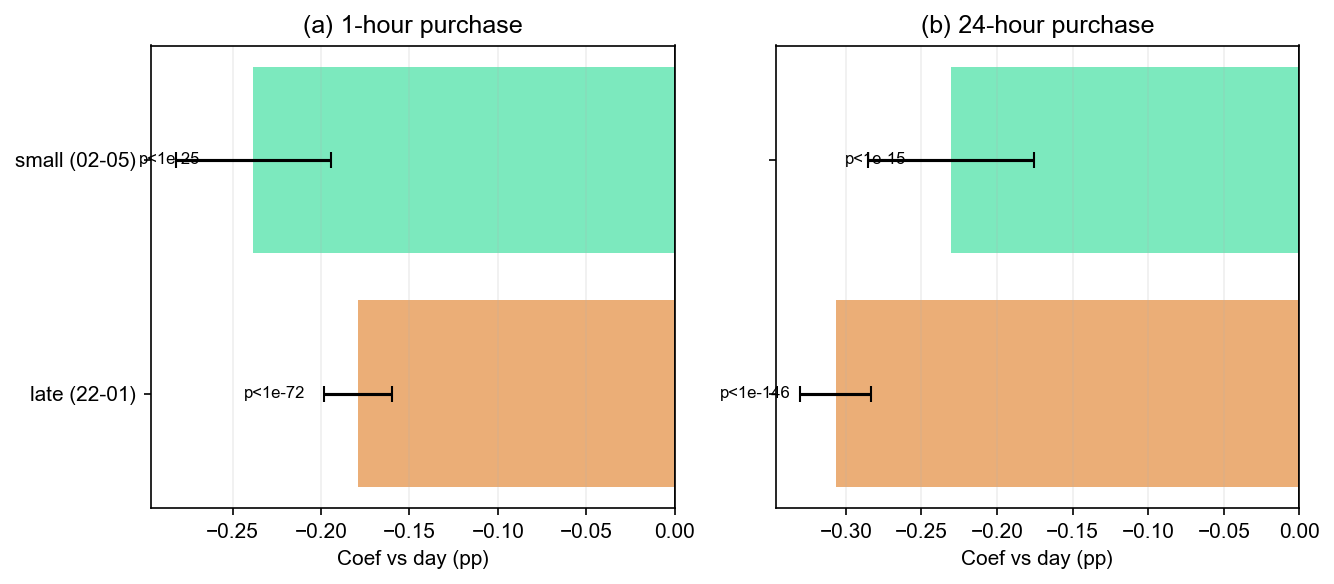

In [14]:
display(Image(filename=str(FIG / '02_bin_comparison.png')))

### 4.1 Pre-specified robustness checks

In [15]:
rob = pd.read_csv(RES / 'robustness.csv').query("cluster != 'user_id+dayhour' or robustness == 'S4_cluster_user_dayhour'")
r = rob[rob.term.isin(['late', 'small'])].copy()
r['est'] = r.coef.map('{:+.3f}'.format) + ' [' + r.ci_low.map('{:.3f}'.format) + ', ' + r.ci_high.map('{:.3f}'.format) + ']'
rt = r.pivot_table(index='robustness', columns=['term', 'outcome'], values='est', aggfunc='first')
display(rt)
neg = r[r.term == 'late']
print('late: all coefficients negative and CIs exclude 0 in', int((neg.ci_high < 0).sum()), 'of', len(neg), 'rows')

term                                        late                                                                      small                                                  
outcome                                       y1                     y10m                       y2                       y1                     y10m                       y2
robustness                                                                                                                                                                   
S1_no_controls           -0.178 [-0.197, -0.158]                      NaN  -0.309 [-0.332, -0.285]  -0.234 [-0.278, -0.190]                      NaN  -0.226 [-0.281, -0.171]
S2_plus_prior_1h_pv      -0.176 [-0.196, -0.157]                      NaN  -0.298 [-0.321, -0.275]  -0.236 [-0.280, -0.193]                      NaN  -0.225 [-0.280, -0.170]
S3_y1_10min                                  NaN  -0.075 [-0.089, -0.062]                      NaN                      NaN  -0.115 [-0.145, -0.085]                      NaN
S4_cluster_user_dayhour  -0.179 [-0.205, -0.154]  -0.075 [-0.087, -0.063]  -0.307 [-0.343, -0.271]  -0.238 [-0.283, -0.193]  -0.115 [-0.142, -0.088]  -0.230 [-0.282, -0.178]
S5_washout72             -0.165 [-0.189, -0.142]                      NaN  -0.291 [-0.319, -0.263]  -0.198 [-0.253, -0.143]                      NaN  -0.168 [-0.237, -0.099]
S6_excl_top1pct          -0.181 [-0.202, -0.161]                      NaN  -0.311 [-0.336, -0.287]  -0.248 [-0.294, -0.202]                      NaN  -0.239 [-0.297, -0.181]
S7_replication           -0.167 [-0.186, -0.147]                      NaN  -0.298 [-0.321, -0.274]  -0.267 [-0.309, -0.226]                      NaN  -0.255 [-0.308, -0.201]
main                     -0.179 [-0.198, -0.160]                      NaN  -0.307 [-0.330, -0.284]  -0.238 [-0.282, -0.194]                      NaN  -0.230 [-0.285, -0.175]

late: all coefficients negative and CIs exclude 0 in 16 of 16 rows


The seven checks are: no controls (S1); add the user's views in the hour before `t0` as a session-intensity control (S2);
10-minute outcome (S3); cluster by user and day-hour (S4); 72-h history washout (S5); drop the top 1% heaviest users (S6);
replication on disjoint users (S7). The late-night gap keeps its sign and its CI excludes 0 in every check.

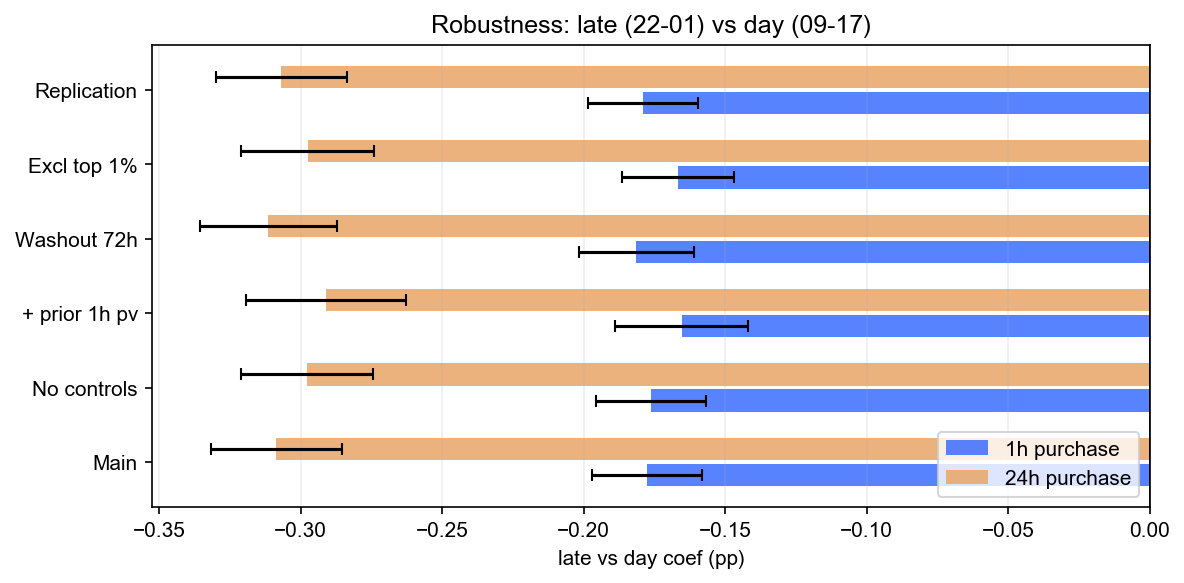

In [16]:
display(Image(filename=str(FIG / '03_robustness.png')))

In [17]:
y3 = pd.read_csv(RES / 'secondary_y3.csv')
y3[['term', 'coef', 'ci_low', 'ci_high', 'p', 'n', 'y_mean']].round(4)

,term,coef,ci_low,ci_high,p,n,y_mean
0,evening,-0.1053,-0.1174,-0.0932,0.0000,9282560,0.3226
1,late,-0.1306,-0.1440,-0.1172,0.0000,9282560,0.3226
2,small,0.0055,-0.0289,0.0400,0.7524,9282560,0.3226
3,morning,0.0571,0.0354,0.0788,0.0000,9282560,0.3226
4,l_hpv24,-0.0275,-0.0315,-0.0234,0.0000,9282560,0.3226
5,hist_buy24,-0.2464,-0.2620,-0.2309,0.0000,9282560,0.3226
6,l_pop,-0.0504,-0.0583,-0.0426,0.0000,9282560,0.3226


**Secondary (descriptive): among episodes not bought in the first hour, who buys in hours 1–24?** Late night stays lower
(−0.131 pp), while small hours are indistinguishable from daytime (+0.006 pp, CI spans 0). This conditions on a post-`t0` state, so it is
only a hint. Section 5 tests the same question properly with survival models.

## 5. Survival analysis: lost purchases or delayed purchases?

A lower 1-h purchase rate is consistent with two stories: night viewers *never* buy (lost demand), or they buy the next
morning (delayed demand). The business answer differs. Lost demand means bidding less; delayed demand means judging night
traffic by 24-h conversion and not by instant conversion.

**Design.**
- Users are split by md5 bucket into train (0–59), validation (60–79) and test (80–99), with no user in more than one split. Models
  are fit on train. Validation is used only for Causal Forest early stopping. Test is used for out-of-sample checks.
- **Event:** first purchase of the item within 24 h of `t0`. Episodes with no purchase, or a purchase after 24 h, are censored
  at 24 h.
- **Cox proportional hazards:** HR < 1 means a lower purchase hazard than in the daytime.
  - M1 has the bin dummies only.
  - M2 adds the controls and day dummies.
  - M3 is stratified by user-activity decile × item-popularity decile × day.
- **Piecewise Cox:** separate fits for hours 0–1 and 1–24, the latter among episodes still at risk at 1 h. *Delayed* means the
  1–24 h HR is not below 1; *lost* means it is.
- **Standard errors:** clustered by user.
- **Implementation:** statsmodels and lifelines cannot fit 30.8 M rows in memory, so `src/fastcox.py` implements Cox with
  Breslow ties and Lin–Wei cluster-robust SE. It is checked against both libraries below.

In [18]:
fv = json.loads((RES / 'features_verification.json').read_text())
display(pd.DataFrame({'episodes': fv['split_sizes'], 'users': fv['split_users']}))
print('user overlap between splits:', fv['split_user_overlap'])
fc = json.loads((RES / 'fastcox_verification.json').read_text())
print('FastCox vs statsmodels PHReg: max |coef diff|', fc['vs_statsmodels']['max_abs_coef_diff'],
      '| robust SE ratio', [round(x, 5) for x in fc['vs_statsmodels']['robust_se_ratio_range']])
print('FastCox vs lifelines (clustered, no ties): max |coef diff|', fc['no_ties_vs_lifelines_cluster']['max_abs_coef_diff'])

,episodes,users
train,30774519,590074
val,10271057,196248
test,10270936,196810


user overlap between splits: {'train&val': 0, 'train&test': 0, 'val&test': 0}
FastCox vs statsmodels PHReg: max |coef diff| 3.9399594697897555e-12 | robust SE ratio [1.00006, 1.00006]
FastCox vs lifelines (clustered, no ties): max |coef diff| 3.372775985466259e-05


### 5.1 Live recomputation: cumulative purchase curves on the test split

In [19]:
from adv_common import load
surv = importlib.import_module('06_survival')
te = load([(80, 99)])
cum_live = surv.describe(te).set_index('bin')
cum_saved = pd.read_csv(RES / 'survival_cumulative_by_bin_full.csv').set_index('bin').loc[cum_live.index, cum_live.columns]
assert np.allclose(cum_live.to_numpy(float), cum_saved.to_numpy(float))
print(f'live test-set curves equal saved results ({len(te):,} test episodes)')
del te
cum_saved.reindex(ORDER).round(3)

live test-set curves equal saved results (10,270,936 test episodes)


,episodes,users,cum_buy_pct_0.166667h,cum_buy_pct_1h,cum_buy_pct_3h,cum_buy_pct_6h,cum_buy_pct_12h,cum_buy_pct_24h,buyers_24h,median_delay_min_buyers24h,share_of_24h_buys_within_1h_pct
bin,,,,,,,,,,,
day,4464366,187517,0.378,0.778,0.917,1.015,1.097,1.160,51769,20.800,67.056
evening,2749680,170504,0.318,0.677,0.781,0.810,0.826,0.939,25809,18.533,72.103
late,2029009,140203,0.289,0.564,0.590,0.594,0.667,0.804,16313,17.183,70.110
small,276719,31223,0.243,0.469,0.506,0.571,0.712,0.847,2343,30.900,55.356
morning,751162,95862,0.275,0.540,0.669,0.786,0.895,0.972,7305,37.500,55.483


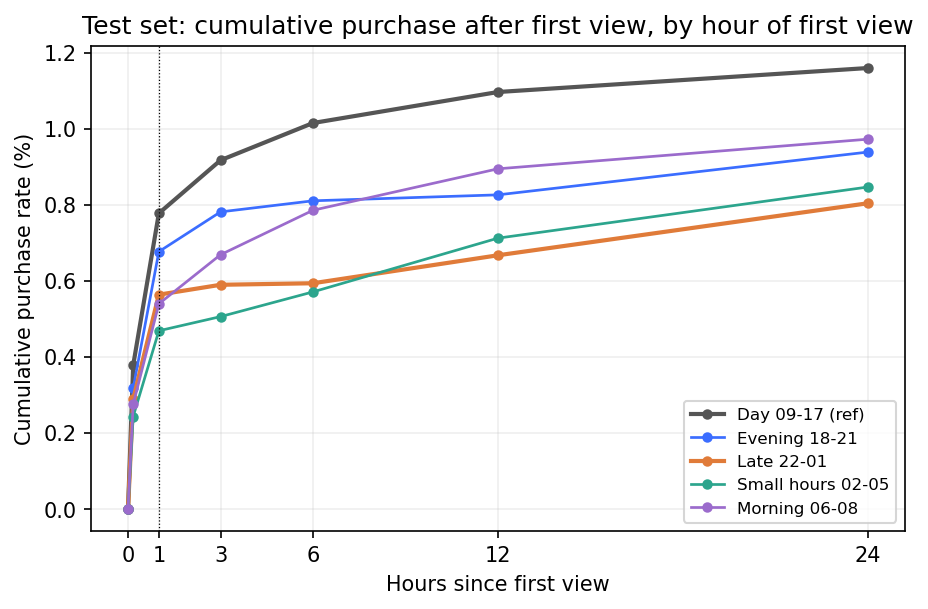

In [20]:
display(Image(filename=str(FIG / '04_cumulative_purchase_by_bin.png')))

**Figure 04.** Cumulative share of test-set first views bought within *h* hours.
- **Daytime** leads from 10 minutes onwards and is never caught.
- **Late night** is almost flat between 1 h and 6 h, when most viewers are presumably asleep, and ends at 0.80% against 1.16% for
  daytime.
- **Small hours** catch up visibly between 6 h and 24 h, the next morning.

In [21]:
sm = pd.read_csv(RES / 'survival_models_full.csv')
cx = sm[sm.term.isin(['late', 'small']) & sm.model.isin(['M1_bins', 'M2_controls', 'M3_stratified', 'PW_0_1h', 'PW_1h_24h'])].copy()
cx['HR [95% CI]'] = cx.hr.map('{:.3f}'.format) + ' [' + cx.hr_ci_low.map('{:.3f}'.format) + ', ' + cx.hr_ci_high.map('{:.3f}'.format) + ']'
ct = cx.pivot_table(index='model', columns='term', values='HR [95% CI]', aggfunc='first')
ct['n'] = cx.groupby('model').n.first(); ct['events'] = cx.groupby('model').events.first()
display(ct.reindex(['M1_bins', 'M2_controls', 'M3_stratified', 'PW_0_1h', 'PW_1h_24h']))
aft = sm[(sm.model == 'AFT_weibull_naive_se') & sm.term.isin(['late', 'small'])][['term', 'time_ratio']]
sj = json.loads((RES / 'survival_full.json').read_text())
print('Weibull AFT time ratios (naive SE, direction only):', dict(zip(aft.term, aft.time_ratio.round(2))), '| shape rho', round(sj['aft_rho'], 3))
print('test-set C-index:', {k: round(v, 3) for k, v in sj['c_index_test'].items()})

term,late,small,n,events
model,,,,
M1_bins,"0.685 [0.676, 0.695]","0.724 [0.700, 0.748]",30774519,308698
M2_controls,"0.705 [0.696, 0.715]","0.743 [0.719, 0.768]",30774519,308698
M3_stratified,"0.703 [0.694, 0.713]","0.751 [0.726, 0.776]",30774519,308698
PW_0_1h,"0.741 [0.728, 0.754]","0.627 [0.599, 0.655]",30774519,208290
PW_1h_24h,"0.635 [0.621, 0.649]","0.975 [0.932, 1.021]",30566229,100408


Weibull AFT time ratios (naive SE, direction only): {'late': 3.82, 'small': 3.08} | shape rho 0.261
test-set C-index: {'M1_bins': 0.538, 'M2_controls': 0.624}


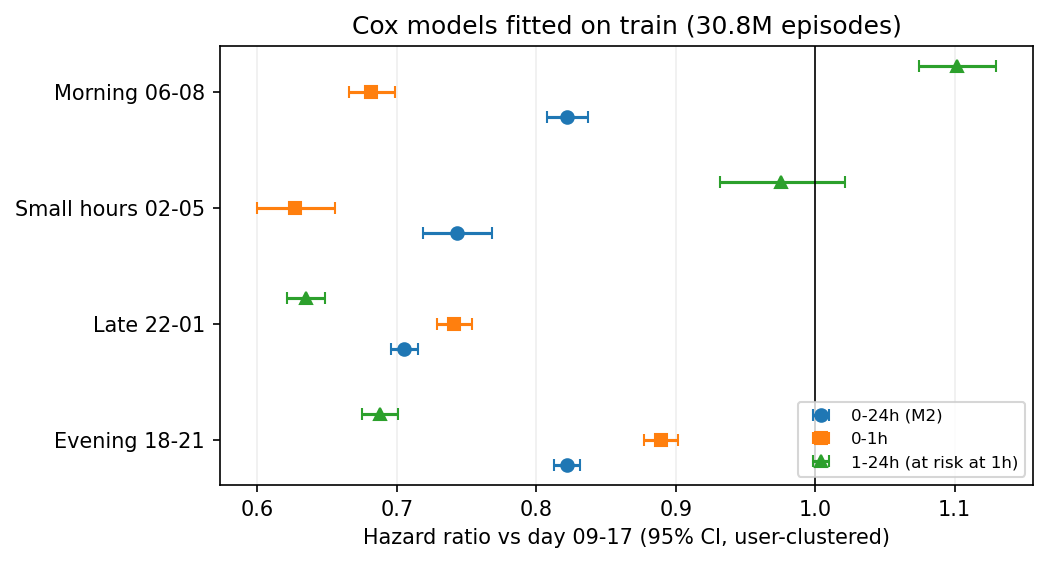

In [22]:
display(Image(filename=str(FIG / '05_cox_piecewise_hr.png')))

**Interpretation.**
- **Late night is lost demand.** HR is about 0.70 over 24 h (M2 0.705, 95% CI 0.696–0.715) and stable under stratification (M3).
  The piecewise model shows the hazard is *lower* after the first hour (HR 0.635) than within it (0.741). A late-night viewer who
  has not bought after an hour is even less likely than a daytime viewer to come back and buy.
- **Small hours are delayed demand.** Within the first hour HR is 0.627, but for hours 1–24 HR is 0.975 with a CI that includes 1.
  Small-hours viewers who did not buy at once buy later at daytime speed.
- **AFT.** The Weibull model gives the same direction: purchase time is stretched by about 3.8× for late night and 3.1× for small
  hours (naive SE, direction only). Shape ρ = 0.26 means the purchase hazard is highest right after viewing and decays fast.
- **Prediction.** The test-set C-index is 0.538 for bins only and 0.624 with controls. Time of day alone predicts little; the
  goal is to compare bins, not to forecast individual purchases.

## 6. Causal Forest: for whom is the late-night gap larger?

**Why.** A single average gap may hide segments where night traffic is fine, or even better than daytime. Bidding rules
need to know whether the gap varies and where.

**Design (`CausalForestDML`, econml 0.17).**
- **Sample:** first views late at night (treatment T = 1) or in the daytime (T = 0); other bins are dropped.
- **Outcome:** `Y1` in percentage points.
- **Features `X`:** measured before `t0` only.
  - User's views in the previous 24 h and 1 h, and any purchase in the previous 24 h.
  - Item views and purchases by everyone in the previous 24 h.
  - The user's cumulative views, favourites, carts and purchases in the study period before `t0`.
  - Day, and a weekend flag.
- **Nuisance models:** LightGBM, with early stopping on the validation split.
- **Forest:** 1,000 honest trees, cross-fitting grouped by user, `max_samples = 0.05`. The econml default of 0.45 would
  pre-allocate about 70 GB.
- **Test-set evaluation**, user-clustered:
  - out-of-sample DML ATE;
  - BLP calibration: β > 0 means the predicted heterogeneity is real;
  - GATES: the effect within quintiles of predicted CATE;
  - CLAN: feature means per quintile.

In [23]:
cf = json.loads((RES / 'causal_forest_full.json').read_text())
print(f"train: {cf['n_train']:,} episodes, {cf['train_users']:,} users | LightGBM rounds: {cf['nuisance_rounds']}")
rows = []
for s in ['val', 'test']:
    v = cf[s]
    rows.append({'sample': s, 'episodes': v['n'], 'users': v['users'], 'late_share': round(v['treated_share'], 3),
                 'ATE_pp': round(v['dml_ate']['coef'], 3), 'ATE_CI': np.round(v['dml_ate']['ci'], 3).tolist(),
                 'BLP_beta': round(v['blp']['beta'], 2), 'BLP_beta_CI': np.round(v['blp']['beta_ci'], 2).tolist(),
                 'share_CATE<0': round(v['cate_pred']['share_negative'], 4)})
display(pd.DataFrame(rows).set_index('sample'))
q = cf['test']['gates_q5_minus_q1']
print(f"test GATES Q5 - Q1: {q['diff']:+.3f} pp, 95% CI [{q['ci'][0]:.3f}, {q['ci'][1]:.3f}]")
fe = prim.query("term == 'late' and outcome == 'y1'").iloc[0]
print(f"for comparison, FE M2 late vs day on Y1: {fe.coef:+.3f} pp [{fe.ci_low:.3f}, {fe.ci_high:.3f}]")

train: 19,509,321 episodes, 581,821 users | LightGBM rounds: {'y': 163, 't': 1200}


,episodes,users,late_share,ATE_pp,ATE_CI,BLP_beta,BLP_beta_CI,share_CATE<0
sample,,,,,,,,
val,6502143,193577,0.313,-0.174,"[-0.192, -0.156]",1.10,"[0.91, 1.29]",0.9986
test,6493375,194123,0.312,-0.181,"[-0.199, -0.163]",1.26,"[1.05, 1.47]",0.9986


test GATES Q5 - Q1: +0.391 pp, 95% CI [0.330, 0.452]
for comparison, FE M2 late vs day on Y1: -0.179 pp [-0.198, -0.160]


The out-of-sample ATE on 6.49 M unseen test episodes (−0.181 pp) is almost identical to the fixed-effects estimate (−0.179 pp),
even though the two methods share no code and use different samples. BLP β = 1.26 (CI 1.05–1.47) is clearly above 0, so the
forest's ranking of who has a bigger gap holds out of sample. 99.9% of predicted effects are negative: no segment where night
traffic converts better was found.

In [24]:
g = pd.DataFrame(cf['test']['gates'])
g['CI'] = g.ci.map(lambda c: f'[{c[0]:.3f}, {c[1]:.3f}]')
g['effect_over_day_rate_pct'] = g.coef / g.raw_y1_day_pp * 100
g['raw_late_over_day'] = g.raw_y1_late_pp / g.raw_y1_day_pp
cols = ['quintile', 'n', 'coef', 'CI', 'raw_y1_day_pp', 'raw_y1_late_pp', 'effect_over_day_rate_pct', 'raw_late_over_day',
        'mean_l_pop24', 'mean_l_ibuy24', 'mean_l_ubuy', 'mean_hist_buy24']
g[cols].round(3).set_index('quintile')

,n,coef,CI,raw_y1_day_pp,raw_y1_late_pp,effect_over_day_rate_pct,raw_late_over_day,mean_l_pop24,mean_l_ibuy24,mean_l_ubuy,mean_hist_buy24
quintile,,,,,,,,,,,
1,1298675,-0.427,"[-0.485, -0.368]",1.633,1.191,-26.144,0.729,1.294,0.313,0.765,0.309
2,1298675,-0.244,"[-0.281, -0.206]",0.992,0.720,-24.540,0.725,2.103,0.402,0.611,0.247
3,1298675,-0.139,"[-0.168, -0.110]",0.642,0.481,-21.622,0.750,2.847,0.400,0.565,0.233
4,1298675,-0.065,"[-0.087, -0.042]",0.384,0.301,-16.795,0.782,3.666,0.438,0.484,0.186
5,1298675,-0.036,"[-0.052, -0.019]",0.215,0.160,-16.696,0.743,4.657,0.437,0.300,0.096


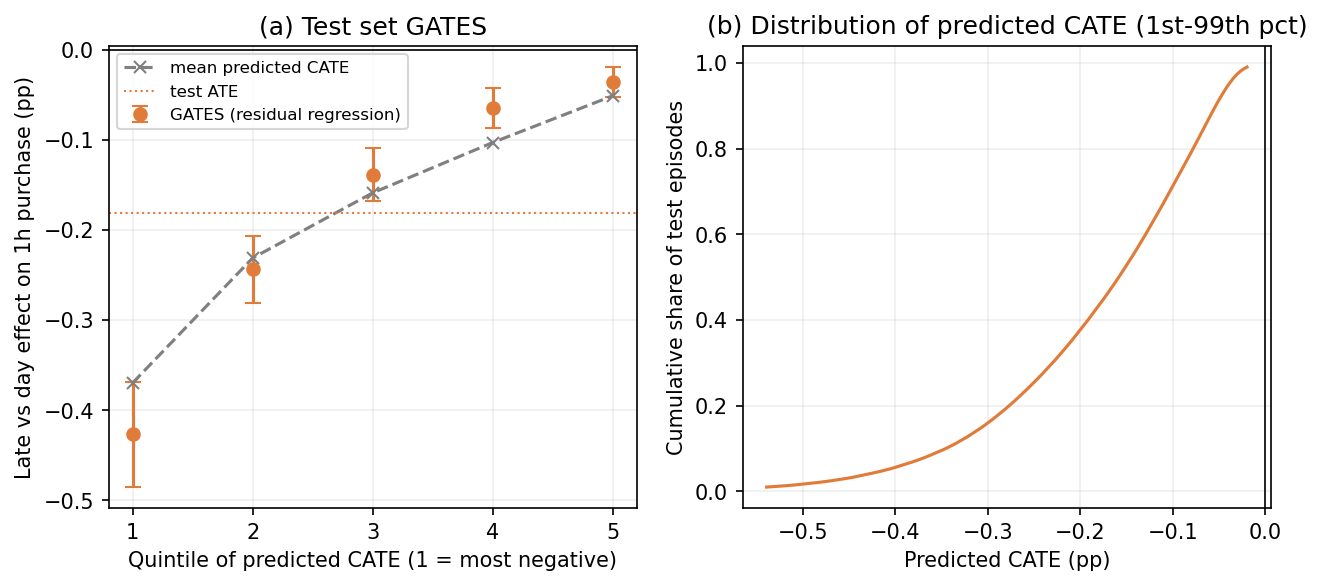

In [25]:
display(Image(filename=str(FIG / '06_causal_forest_gates.png')))

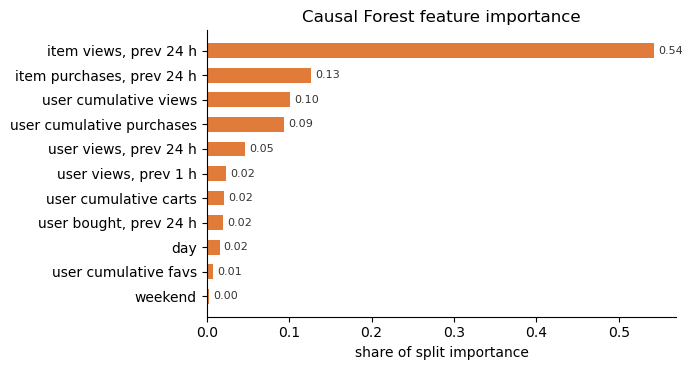

In [26]:
imp = pd.Series(cf['feature_importances']).sort_values()
labels = {'l_pop24': 'item views, prev 24 h', 'l_ibuy24': 'item purchases, prev 24 h', 'l_upv': 'user cumulative views',
          'l_ubuy': 'user cumulative purchases', 'l_hpv24': 'user views, prev 24 h', 'l_hpv1h': 'user views, prev 1 h',
          'l_ucart': 'user cumulative carts', 'hist_buy24': 'user bought, prev 24 h', 'day': 'day', 'l_ufav': 'user cumulative favs',
          'is_weekend': 'weekend'}
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh([labels[i] for i in imp.index], imp.values, color='#E07B39', height=.6)
for y, v in enumerate(imp.values):
    ax.text(v + .005, y, f'{v:.2f}', va='center', fontsize=8, color='#333333')
ax.set_xlabel('share of split importance'); ax.set_title('Causal Forest feature importance')
ax.spines[['top', 'right']].set_visible(False); plt.tight_layout(); plt.show()

**Interpretation: the heterogeneity is mostly scale.**
- **Where the gap is largest.** The forest splits mainly on item popularity (importance 0.54). The most negative quintile (Q1,
  −0.43 pp) is long-tail items and users who have already bought in the period. These are the situations with the highest daytime
  conversion (1.63%), so they also have the most to lose at night.
- **Where it is smallest.** Q5 (−0.04 pp) is popular items, where sightseeing traffic rarely converts at any hour.
- **In relative terms the gap is similar everywhere.** Divided by the daytime rate, it ranges only from −26% (Q1) to −17% (Q5),
  and the raw late/day ratio is 0.72–0.78 in every quintile. These ratios are descriptive and have no CIs of their own.
- **Caution on overlap.** The propensity range reaches 0.95, so some items are viewed almost only at one time of day. CATEs in
  extreme-propensity regions should be read with care. CATE is a conditional difference in association, not an individual causal
  effect of the clock.

## 7. Verification summary

In [27]:
v = json.loads((RES / 'verification.json').read_text())
rb = v['rebuild']
summary = pd.DataFrame([
    ('Independent row-by-row rebuild of 400 users', f"{rb['pipeline_episodes']:,} episodes, mismatched fields = {sum(rb['field_mismatches'].values())}, one-side-only = {rb['only_one_side']}"),
    ('Item popularity recount (300 episodes)', f"mismatches = {v['pop24_mismatches_of_300']}"),
    ('Pre-t0 user/item features recount (300 episodes)', f"mismatches = {sum(fv['feature_mismatches_of_300'].values())}"),
    ('Absorbed FE vs explicit dummy OLS', f"max |coef diff| = {v['fe_vs_dummies']['max_abs_coef_diff']:.1e}, SE ratio {v['fe_vs_dummies']['se_ratio_min']:.6f}-{v['fe_vs_dummies']['se_ratio_max']:.6f}"),
    ('FastCox vs statsmodels PHReg', f"max |coef diff| = {fc['vs_statsmodels']['max_abs_coef_diff']:.1e}"),
    ('Train / val / test user overlap', str(fv['split_user_overlap'])),
    ('This notebook: live descriptives, M2 refit, test curves', 'equal to saved results (asserted above)'),
], columns=['check', 'result']).set_index('check')
summary

,result
check,
Independent row-by-row rebuild of 400 users,"21,133 episodes, mismatched fields = 0, one-si..."
Item popularity recount (300 episodes),mismatches = 0
Pre-t0 user/item features recount (300 episodes),mismatches = 0
Absorbed FE vs explicit dummy OLS,"max |coef diff| = 1.5e-13, SE ratio 1.000000-1..."
FastCox vs statsmodels PHReg,max |coef diff| = 3.9e-12
Train / val / test user overlap,"{'train&val': 0, 'train&test': 0, 'val&test': 0}"
"This notebook: live descriptives, M2 refit, test curves",equal to saved results (asserted above)


## 8. Conclusions and business implications

**Answer.** Late-night browsing on Taobao behaves like idle scrolling, not impulse buying.
- **Within user and item.** With user, item and day held fixed, a product first viewed at 22–01 is about 0.18 pp less likely to be
  bought within an hour, and 0.31 pp less likely within a day, than one first viewed in the daytime. That is roughly a quarter of
  the daytime rate.
- **Lost vs delayed.** Survival models separate the two night bins. Late-night demand is mostly *lost*: the gap widens after the
  first hour. Small-hours demand is mostly *delayed*: those viewers buy the next day at daytime speed.
- **Heterogeneity.** The gap is negative for 99.9% of episodes. It is largest in absolute terms for long-tail items and returning
  buyers, and similar in relative terms (−17% to −26%) across segments.

**Implications.**
1. **Hour-of-day bids.** Value late-night (22–01) clicks at roughly three-quarters of daytime clicks for conversion campaigns,
   unless the goal is brand exposure.
2. **Attribution windows.** Judge small-hours (02–05) traffic on 24-h conversion, not instant conversion. Judged on 1-h
   conversion it looks as bad as late night, but much of the gap is made up by the next day.
3. **Where to cut.** In absolute terms the late-night discount matters most for long-tail items and repeat buyers. A proportional
   discount is roughly right across segments, so no segment needs a night-time premium.

**Limitations.**
- **Observational data.** Fixed effects remove stable user and item differences but not within-session intent. "Idle scrolling"
  describes a behaviour pattern, not an identified psychological mechanism.
- **Short window and missing fields.** Only 9 days, with no price, promotion or dwell-time data. Late-night traffic could differ in
  promotion mix.
- **Scope.** "First view" means first *observed* view, and about 40% of purchases have no earlier view in the window.
- **Sleep.** The flat late-night curve between 1 h and 6 h partly reflects sleep. Purchase *speed* in those hours is not comparable
  across bins.
- **Test-split leak in the smoke run.** One test bucket (80) was used in the smoke run before the full run. This is disclosed in
  `POST_PLAN_DEVIATIONS.md`.